In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 04 · Bivariate Analysis

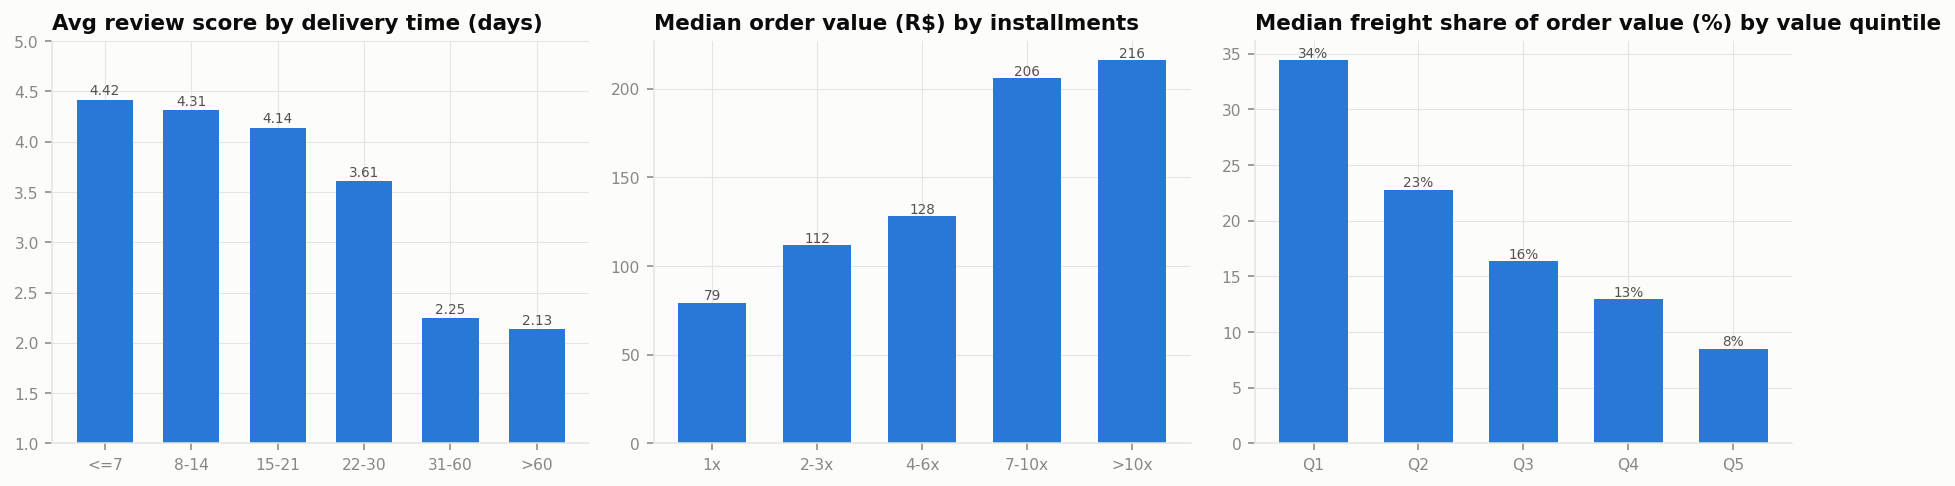

In [2]:
img('04_data_profiling_eda/reports/figures/bivariate_relationships.png')

In [3]:
s = json.loads((ROOT / '04_data_profiling_eda/reports/eda_summary.json').read_text())
{k: v for k, v in s.items() if k not in ('high_corr_pairs',)}

{'one_time_share': 0.9700442515896202,
 'delivery_vs_review_spearman': -0.23444514991309293,
 'review_on_time': 4.291157408445651,
 'review_late': 2.270617748510505,
 'installments_vs_value_spearman': 0.3811624881210881,
 'median_monetary_repeat': 225.63,
 'median_monetary_one_time': 105.38,
 'repeat_vs_one_time_p': 0.0,
 'aov_repeat': 110.04,
 'aov_one_time': 105.38,
 'pca_explained_first3': [0.24310417886210134,
  0.17598324626887152,
  0.13414091635662115]}

In [4]:
db.query("SELECT is_late, round(avg(review_score),2) review, count(*) orders FROM dw.fact_orders WHERE is_revenue AND is_late IS NOT NULL GROUP BY 1")

,is_late,review,orders
0,False,4.29,89672
1,True,2.27,6531
